# GLM Tutorial 2: fitting a real neuron with a GLM

**Neural data analysis course**

In tutorial 1 we built up the GLM pipeline (stimulus &rarr; linear filter &rarr;
nonlinearity &rarr; noise) on synthetic data. Here we fit the same kind of
model to a real neuron.

**Task.** Two macaque monkeys performed a three-armed bandit task: on each
trial they chose one of three targets, one of which paid out reward on 70% of
presses while the other two paid out on 25%; the identity of the best target
switched every ~40 trials without warning, so the animals had to track recent
outcomes to know when to switch (Ungvárszki et al., 2025,
[bioRxiv](https://www.biorxiv.org/content/10.1101/2025.09.29.679289v1)). While
the animals performed the task, single neurons were recorded from midcingulate
and lateral prefrontal cortex.

**Data.** `glm_monkey_data.csv` holds, for one example neuron and session: the
spike count on each trial (`spike_count`), the chosen and best target
(`choice`, `best_target`), whether that trial was rewarded (`outcome`), the
trial and block index (`trial_id`, `block_id`), and `R_1` ... `R_7` - the
reward outcome (1 = rewarded, 0 = unrewarded) on each of the 7 preceding
trials.

This mirrors **Example 4** from tutorial 1: instead of a continuous stimulus
history, the "design matrix" here is the neuron's own reward history, and we
ask whether - like the monkeys' choices (paper Fig. 1F) and the population
value signal (paper Fig. 4F) - this neuron's firing is shaped by a
recency-weighted integration of past outcomes.

---
# Tutorial slides

The introduction below is presented live together with the slide deck / blackboard
derivations. The slides are linked here for reference:

**Slides:** https://mag.wcoomd.org/uploads/2018/05/blank.pdf
*(placeholder link - replace with the real slide deck URL before the tutorial)*

---
# Setup

In [1]:
# @title Imports
import numpy as np
import xarray as xr
import pandas as pd

import matplotlib.pyplot as plt
from matplotlib.colors import to_rgba, ListedColormap
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from time import time

import statsmodels.api as sm

/home/uzsombi/.config/matplotlib is not a writable directory
Matplotlib created a temporary cache directory at /tmp/matplotlib-bv4ysg1w because there was an issue with the default path (/home/uzsombi/.config/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


In [2]:
def load_monkey_data():
    data = pd.read_csv('glm_monkey_data.csv')
    # shift outcome one back and remove nan rows
    data['outcome'] = data['outcome'].shift(1)
    data = data.dropna(subset=['outcome'])
    # remove colums starting with R_
    data = data.loc[:, ~data.columns.str.startswith('R_')]
    
    return data

In [3]:
# @title Plotting functions (run this cell, no need to read the details)

def plot_blocks(df, target_colors=None, spike_color="#b35a5f",
                block_ids=None, bg_alpha=0.2, figsize_per_block=(6, 1.6)):
    """
    One row per block. Top strip: chosen target (color), filled = rewarded,
    empty = unrewarded, background = best target's color. Bottom: spike count.

    Expected columns: spike_count, trial_id, block_id, choice, outcome, best_target
    - choice / best_target: target labels (same label set, e.g. 0/1/2)
    - outcome: truthy = rewarded
    """
    targets = sorted(pd.unique(pd.concat([df["choice"], df["best_target"]]).dropna()))
    if target_colors is None:
        palette = ["#f4b183", "#d6a4dc", "#a9c8ef"]  # orange, purple, blue
        target_colors = {t: palette[i % len(palette)] for i, t in enumerate(targets)}

    if block_ids is None:
        block_ids = list(pd.unique(df.sort_values("trial_id")["block_id"]))
    n_blocks = len(block_ids)

    fig = plt.figure(figsize=(figsize_per_block[0], figsize_per_block[1] * n_blocks),
                     constrained_layout=True)
    # one shared grid: [dots, spikes, spacer] per block -> all blocks equal height
    ratios = []
    for _ in range(n_blocks):
        ratios += [1, 3.5, 0.9]
    gs = fig.add_gridspec(3 * n_blocks - 1, 1, height_ratios=ratios[:-1], hspace=0)

    # common x-range and y-range so blocks are comparable
    max_len = df.groupby("block_id").size().max()
    y_max = df["spike_count"].max()

    ax_prev = None
    for i, b in enumerate(block_ids):
        d = df[df["block_id"] == b].sort_values("trial_id")
        x = np.arange(1, len(d) + 1)  # trial in block
        best = d["best_target"].mode().iloc[0]

        ax_dot = fig.add_subplot(gs[3 * i], sharex=ax_prev)
        ax_sp = fig.add_subplot(gs[3 * i + 1], sharex=ax_dot)
        ax_prev = ax_dot

        # ---- top strip: choices & outcomes ----
        ax_dot.set_facecolor(to_rgba(target_colors[best], bg_alpha))
        rewarded = d["outcome"].astype(bool).to_numpy()
        cols = d["choice"].map(target_colors).to_numpy()
        ax_dot.scatter(x, np.zeros_like(x), s=30, linewidths=1.5,
                       edgecolors=cols,
                       facecolors=[c if r else "white" for c, r in zip(cols, rewarded)],
                       zorder=3, clip_on=False)
        ax_dot.set_ylim(-1, 1)
        ax_dot.set_yticks([])
        for s in ax_dot.spines.values():
            s.set_visible(False)
        ax_dot.tick_params(axis="x", bottom=False)
        ax_dot.set_title(f"Block {i + 1}", fontstyle="italic", color="0.35", fontsize=9)

        # ---- bottom: spike count ----
        ax_sp.plot(x, d["spike_count"].to_numpy(), color=spike_color, lw=1.8,
                   solid_joinstyle="miter")
        for yy in (0, y_max):
            ax_sp.axhline(yy, ls="--", lw=1, color="0.4", zorder=0)
        ax_sp.set_ylim(-0.03 * y_max, y_max * 1.03)
        ax_sp.set_yticks([0, y_max])
        ax_sp.set_ylabel("Spikes", fontsize=9)
        ax_sp.spines[["top", "right", "bottom"]].set_visible(False)
        ax_sp.spines["left"].set_linewidth(2)
        ax_sp.set_xlim(0.5, max_len + 0.5)
        ax_sp.set_xticks([t for t in range(5, max_len + 1, 5)])
        if i == n_blocks - 1:
            ax_sp.set_xlabel("Trial in block", fontsize=13)
        else:
            ax_sp.tick_params(axis="x", labelbottom=False)
        ax_dot.tick_params(axis="x", labelbottom=False)

    # legend (outcome + target colors)
    handles = [Line2D([], [], marker="o", ls="", ms=6, color="0.4", label="Rewarded"),
               Line2D([], [], marker="o", ls="", ms=6, mfc="white", mec="0.4",
                      mew=1.5, label="Unrewarded")]
    handles += [Line2D([], [], marker="o", ls="", ms=6, color=target_colors[t],
                       label=f"Target {t}") for t in targets]
    fig.legend(handles=handles, loc="outside upper right", ncol=len(handles),
               frameon=False, fontsize=9)
    return fig

In [4]:
# @title Plotting functions, cont. (run this cell, no need to read the details)

def plot_design_matrix_and_activity(X, Y, window=slice(0, 100)):
    """Binary design matrix (trials x lags) above the spike counts, sharing the trial axis."""
    X_arr = np.asarray(X)[window]
    Y_arr = np.asarray(Y)[window]
    trials = np.arange(len(np.asarray(Y)))[window]
    lag_labels = list(X.columns) if hasattr(X, "columns") else \
        [f"lag {j + 1}" for j in range(X_arr.shape[1])]
    n_lags = X_arr.shape[1]

    fig, (ax_X, ax_Y) = plt.subplots(2, 1, figsize=(10, 4.5), sharex=True,
                                     height_ratios=[1, 0.8])

    cmap = ListedColormap(["lightgrey", "seagreen"])
    ax_X.imshow(X_arr.T, aspect="auto", cmap=cmap, vmin=0, vmax=1,
                interpolation="nearest",
                extent=[trials[0] - 0.5, trials[-1] + 0.5, n_lags - 0.5, -0.5])
    ax_X.set_yticks(range(n_lags))
    ax_X.set_yticklabels(lag_labels)
    ax_X.set_ylabel("trials back")
    ax_X.legend(handles=[Patch(color="lightgrey", label="unrewarded"),
                         Patch(color="seagreen", label="rewarded")],
                loc="lower right", bbox_to_anchor=(1, 1), ncol=2, frameon=False)

    ax_Y.plot(trials, Y_arr, color="k", lw=1, marker="o", ms=3)
    ax_Y.set_ylabel("Spike count")
    ax_Y.set_xlabel("Trial")
    ax_Y.set_xlim(trials[0] - 0.5, trials[-1] + 0.5)

    fig.tight_layout()
    plt.show()

---
# GLM analysis
**Now we look at the data.** We load one example neuron's per-trial data and
look at the raw choices, outcomes, and spike counts across a few blocks of
the task.

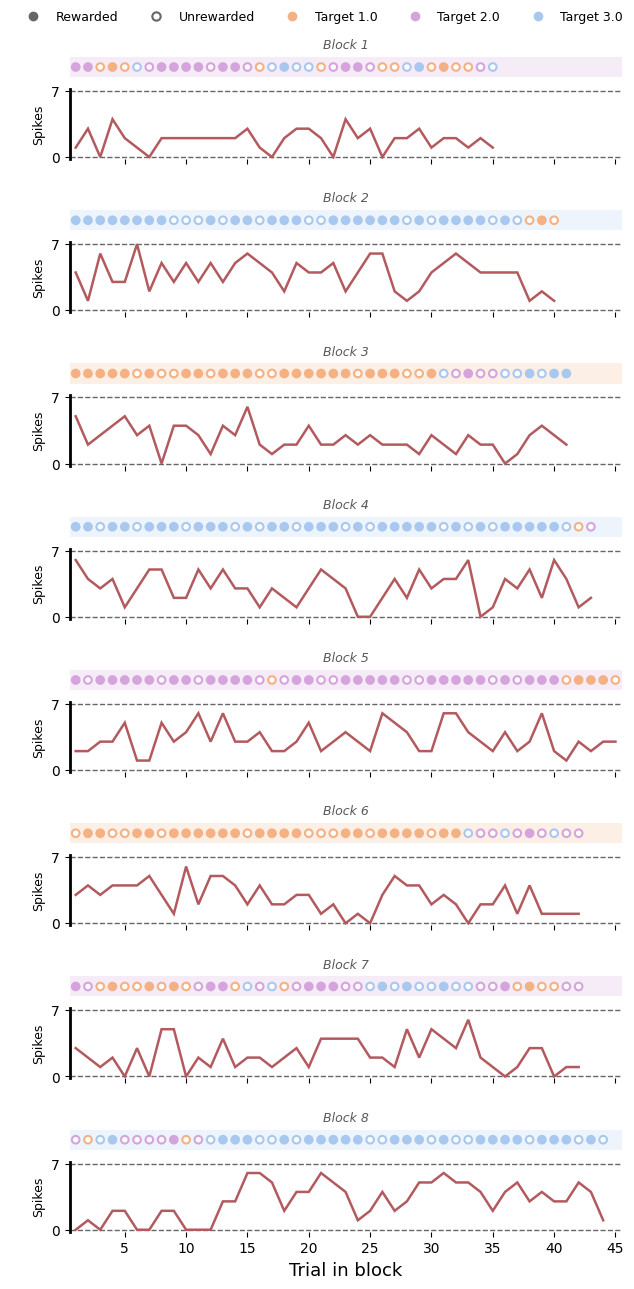

In [5]:
data = load_monkey_data()

fig = plot_blocks(data)
plt.show()

In [6]:
data.head()

,spike_count,trial_id,block_id,choice,outcome,best_target
1,1.0,9.0,0.0,2.0,1.0,2.0
2,3.0,10.0,0.0,2.0,1.0,2.0
3,0.0,11.0,0.0,1.0,0.0,2.0
4,4.0,12.0,0.0,1.0,1.0,2.0
5,2.0,13.0,0.0,1.0,0.0,2.0


**Now we build the design matrix for the GLM.** Each row is one trial;
the columns `R_1` ... `R_7` are the reward outcomes (1 = rewarded, 0 =
unrewarded) on the 7 preceding trials, and the response `Y` is the neuron's
spike count on that trial.

Shape of X: (326, 7)
Shape of Y: (326,)


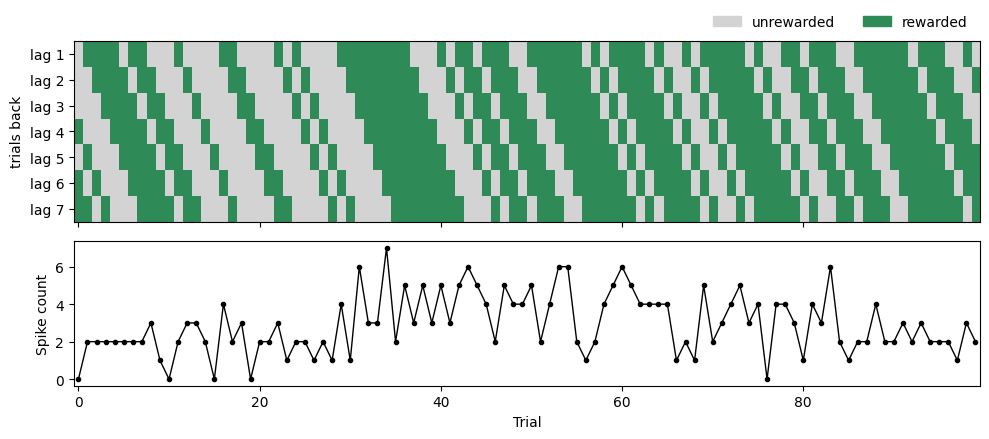

In [7]:

# build design matrix: time lag of 7 trials back: x(t) = [s(t-1), s(t-2), ..., s(t-7)]
def build_design_matrix(s, k):
    """Row t = [s(t), s(t-1), ..., s(t-k+1)] for t = k-1 ... T-1."""
    T = len(s)
    X = np.zeros((T - k + 1, k))
    for j in range(k):
        X[:, j] = s[k - 1 - j:T - j]
    return X

# get spike train Y and outcome variable x
x, Y = data['outcome'].values, data['spike_count'].values

# build design matrix with 7 lags
X = build_design_matrix(x, k=7)
Y = Y[6:]  # align with design matrix (remove first 6 trials that has no 7-trials-ago history)

print("Shape of X:", X.shape)  # design matrix shape (n_trials, n_lags)
print("Shape of Y:", Y.shape)  # response variable shape (n_trials,)

plot_design_matrix_and_activity(X, Y)

**Now we fit the GLM.** As in Example 4 of tutorial 1, we fit
$\lambda = \exp(X\theta)$, $y \sim \text{Poisson}(\lambda)$ - a Poisson GLM
with a log link - so $\hat\theta$ tells us how much each past outcome
contributes to the neuron's firing rate.

In [8]:
# Poisson GLM with a log link: E[Y] = exp(X @ theta)
model = sm.GLM(
    Y, X,
    family=sm.families.Poisson(link=sm.families.links.Log())
)

results = model.fit()
print(results.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:                      y   No. Observations:                  326
Model:                            GLM   Df Residuals:                      319
Model Family:                 Poisson   Df Model:                            6
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -596.57
Date:                Thu, 24 Sep 2026   Deviance:                       313.19
Time:                        14:15:05   Pearson chi2:                     302.
No. Iterations:                     4   Pseudo R-squ. (CS):             0.1348
Covariance Type:            nonrobust                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
x1             0.5151      0.066      7.790      0.0

**Now we visualize the parameters.** The fitted $\hat\theta$ gives one
weight per trial-lag - together they form the neuron's reward-history filter,
exactly like the temporal filter recovered in Example 4 of tutorial 1.

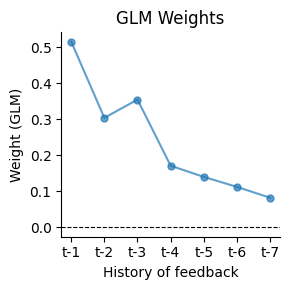

In [9]:
theta_weights = results.params  # one weight per lag: t-1 ... t-7
history_levels = ['t-1', 't-2', 't-3', 't-4', 't-5', 't-6', 't-7']

fig, ax = plt.subplots(figsize=(3, 3))
ax.plot(history_levels, theta_weights, color='tab:blue', alpha=0.7, marker='o', markersize=5, label='GLM Weights')
ax.axhline(0, color='black', lw=0.8, ls='--')
ax.set_ylabel('Weight (GLM)')
ax.set_xlabel('History of feedback')
ax.set_title('GLM Weights')
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
plt.tight_layout()
plt.show()